# GL304 - Atividade 03: Ranqueamento dos municípios paulistas via ISDEL e PROMETHEE II

**Aluno:** André Traquia · **RA:** 185759 · **Turma:** B

Notebook derivado dos códigos do professor (`MQA-S06-A03`, `MQA-S06-A06` e o notebook de apoio do mapa).

Alocação (notebook de alocação de tarefas, Turma B, aluno nº 7, índices 12 e 13 de `itertools.combinations`):

- **Mapa 1 (Combinação A):** Densidade Empresarial, Educação, Tecido Empresarial
- **Mapa 2 (Combinação B):** Densidade Empresarial, Educação, Articulação

Diferença em relação ao notebook de apoio: lá os indicadores são simulados (`np.random.uniform`). Aqui os dados são os reais do ISDEL, lidos da planilha usada em `MQA-S06-A03`.

## 1. Leitura e preparação dos dados do ISDEL

In [1]:
import ssl, unicodedata
import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import matplotlib.pyplot as plt

# Mesma planilha do notebook MQA-S06-A03 do professor
url = 'https://drive.google.com/uc?export=download&id=12b6bvcSe0LXST4_bQX-jC7Q5BsNd_BGS'
df = pd.read_excel(url)

# Linha 2 traz os nomes dos critérios; colunas 0 a 12 = município + 12 indicadores
df = df.iloc[2:, 0:13]
df.columns = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)
df.columns.name = None
df = df.rename(columns={'Municípios': 'Município'})
indicadores = list(df.columns[1:])
df[indicadores] = df[indicadores].astype(float)
print(len(df), 'municípios;', len(indicadores), 'indicadores')
df.head()

645 municípios; 12 indicadores


,Município,Densidade Empresarial,Renda,Educação,Valores Solidários - programas e ações,Tecido Social,Tecido Empresarial,Articulação,Gestão Pública,Participação e Controle Social,Vantagens Locais,Organização Produtiva,Comércio Internacional
0,Adamantina,0.292112,0.709371,0.844012,0.571429,0.003483,0.000000,0.500000,0.695181,0.404762,0.439765,0.491475,0.067792
1,Adolfo,0.294667,0.623339,0.801920,0.000000,0.000657,0.000000,0.000000,0.533664,0.374048,0.413952,0.352418,0.067792
2,Aguaí,0.282476,0.594759,0.771491,0.000000,0.001220,0.002002,0.000000,0.326012,0.400238,0.344832,0.500990,0.067792
3,Águas da Prata,0.270997,0.671739,0.826817,0.000000,0.000258,0.000000,0.083333,0.787747,0.367143,0.424545,0.474748,0.067792
4,Águas de Lindóia,0.435084,0.647601,0.791001,0.000000,0.000610,0.000200,0.250000,0.662081,0.362302,0.400696,0.461352,0.067792


In [2]:
# Seleção das variáveis atribuídas ao aluno
ALUNO = 'André Traquia'
COMB_A = ['Densidade Empresarial', 'Educação', 'Tecido Empresarial']   # Mapa 1
COMB_B = ['Densidade Empresarial', 'Educação', 'Articulação']          # Mapa 2

# Padronização: tudo deve estar entre 0 e 1 (1 = melhor desempenho)
usadas = sorted(set(COMB_A + COMB_B))
resumo = df[usadas].describe().T[['min', 'max', 'mean']]
resumo['valores distintos'] = df[usadas].nunique()
assert df[usadas].min().min() >= 0 and df[usadas].max().max() <= 1
assert df[usadas].notna().all().all()
resumo

,min,max,mean,valores distintos
Articulação,0.000000,1.000000,0.146899,13
Densidade Empresarial,0.078107,1.000000,0.296404,645
Educação,0.658045,0.942459,0.800031,645
Tecido Empresarial,0.000000,1.000000,0.002536,50


## 2. PROMETHEE II

Pesos iguais ($w_k = 1/3$), todos os critérios de maximização e função de preferência usual:
$P_k(a_i,a_j)=1$ se $f_k(a_i)>f_k(a_j)$, senão 0.

As funções seguem o código do professor. A comparação par a par foi vetorizada com NumPy (645 × 645 por critério), o que dá o mesmo resultado dos laços originais em menos tempo.

In [3]:
def tabelaC(df, crit, maximizar=True):
    # P_k(a_i, a_j): 1 se a_i é estritamente melhor que a_j no critério
    v = df[crit].to_numpy()
    return (v[:, None] > v[None, :]) if maximizar else (v[:, None] < v[None, :])

def prometheeII(df, pesos, objetivos):
    m = len(df)
    pi = sum(w * tabelaC(df, c, o) for c, w, o in zip(df.columns, pesos, objetivos))  # pi(a_i, a_j)
    phip = pi.sum(axis=1) / (m - 1)   # fluxo positivo: quanto a_i domina os demais
    phin = pi.sum(axis=0) / (m - 1)   # fluxo negativo: quanto a_i é dominado
    return pd.DataFrame({'Phi+': phip, 'Phi-': phin, 'Phi': phip - phin}, index=df.index)

# Conferência com o exemplo numérico do professor (MQA-S06-A06): Phi = -0.77, 0.00, -0.11, 0.88
ex = pd.DataFrame([[0.5,0.3,0.3],[0.7,0.5,0.5],[0.9,0.5,0.1],[0.9,0.7,0.9]], columns=['C1','C2','C3'])
phi_ex = prometheeII(ex, [0.33]*3, [True]*3)['Phi'].round(2).tolist()
assert phi_ex == [-0.77, 0.0, -0.11, 0.88], phi_ex
print('Exemplo do professor reproduzido:', phi_ex)

Exemplo do professor reproduzido: [-0.77, 0.0, -0.11, 0.88]


In [4]:
def ranquear(criterios):
    r = prometheeII(df[criterios], [1/3]*3, [True]*3)
    out = pd.concat([df[['Município'] + criterios], r], axis=1)
    out['Ranking'] = out['Phi'].rank(ascending=False, method='min').astype(int)
    return out

rA, rB = ranquear(COMB_A), ranquear(COMB_B)
for nome, r in [('Mapa 1', rA), ('Mapa 2', rB)]:
    assert abs(r['Phi'].sum()) < 1e-9          # o fluxo líquido soma zero
    print(nome, '| soma de Phi =', round(r['Phi'].sum(), 12), '| Phi min/max =', round(r['Phi'].min(), 4), round(r['Phi'].max(), 4))

Mapa 1 | soma de Phi = -0.0 | Phi min/max = -0.7712 0.9079
Mapa 2 | soma de Phi = -0.0 | Phi min/max = -0.8763 0.9167


## 3. Malha do IBGE e junção com os 645 municípios

In [5]:
class TLSAdapter(requests.adapters.HTTPAdapter):
    def init_poolmanager(self, *args, **kwargs):
        ctx = ssl.create_default_context()
        ctx.set_ciphers("DEFAULT@SECLEVEL=1")
        ctx.options |= 0x4   # OP_LEGACY_SERVER_CONNECT
        kwargs["ssl_context"] = ctx
        return super(TLSAdapter, self).init_poolmanager(*args, **kwargs)

with requests.session() as s:
    s.mount("https://", TLSAdapter())
    municipios_json = s.get('https://servicodados.ibge.gov.br/api/v2/malhas/35/?formato=application/vnd.geo+json&resolucao=5').json()
    districts = s.get('https://servicodados.ibge.gov.br/api/v1/localidades/estados/35/municipios').json()

# A planilha do ISDEL só traz o nome; o código IBGE vem da API de localidades, casando pelo nome padronizado
def norm(t):
    return unicodedata.normalize('NFKD', t).encode('ascii', 'ignore').decode().lower().replace('-', ' ').replace("'", ' ').strip()

grafia = {'florinia': 'florinea', 'sao luis do paraitinga': 'sao luiz do paraitinga'}  # grafias que diferem do IBGE
ibge = pd.DataFrame([{'chave': norm(d['nome']), 'codarea': d['id'],
                      'Microrregião': d['microrregiao']['nome'],
                      'Mesorregião': d['microrregiao']['mesorregiao']['nome']} for d in districts])
df['chave'] = df['Município'].map(norm).replace(grafia)
geo = df[['Município', 'chave']].merge(ibge, on='chave', how='left', validate='one_to_one')
assert geo['codarea'].notna().all(), geo[geo['codarea'].isna()]

gdf_sp = gpd.GeoDataFrame.from_features(municipios_json['features'])
gdf_sp['codarea'] = gdf_sp['codarea'].astype(int)
gdf_sp = gdf_sp.merge(geo, on='codarea', how='left')
assert len(gdf_sp) == 645 and gdf_sp['Município'].notna().all()
print('Municípios na malha:', len(gdf_sp), '| casados com o ISDEL:', int(gdf_sp['Município'].notna().sum()))

for r in (rA, rB):
    r[['codarea', 'Microrregião', 'Mesorregião']] = geo[['codarea', 'Microrregião', 'Mesorregião']].values

Municípios na malha: 645 | casados com o ISDEL: 645


## 4. Rankings

In [6]:
rA.sort_values('Ranking').to_csv('GL304_A3_ranking_mapa1.csv', index=False, encoding='utf-8-sig')
rB.sort_values('Ranking').to_csv('GL304_A3_ranking_mapa2.csv', index=False, encoding='utf-8-sig')
cols = ['Ranking', 'Município', 'Mesorregião', 'Phi']
print('MAPA 1 -', ', '.join(COMB_A))
display(rA.sort_values('Ranking')[cols + COMB_A].head(10).round(4))
display(rA.sort_values('Ranking')[cols + COMB_A].tail(10).round(4))

MAPA 1 - Densidade Empresarial, Educação, Tecido Empresarial


,Ranking,Município,Mesorregião,Phi,Densidade Empresarial,Educação,Tecido Empresarial
534,1,Santana de Parnaíba,Metropolitana de São Paulo,0.9079,0.4402,0.8737,0.0052
547,2,São Caetano do Sul,Metropolitana de São Paulo,0.8520,0.4028,0.9425,0.0022
64,3,Barueri,Metropolitana de São Paulo,0.8282,0.3586,0.8565,0.0458
489,4,Ribeirão Preto,Ribeirão Preto,0.8271,0.3610,0.8551,0.0216
558,5,São José do Rio Preto,São José do Rio Preto,0.8199,0.3539,0.8691,0.0066
544,6,Santos,Metropolitana de São Paulo,0.8168,0.3292,0.8952,0.0184
128,7,Cedral,São José do Rio Preto,0.8012,0.4042,0.8574,0.0018
631,8,Valinhos,Campinas,0.7645,0.3230,0.8825,0.0046
550,9,São João da Boa Vista,Campinas,0.7614,0.3328,0.8578,0.0046
67,10,Bauru,Bauru,0.7412,0.3276,0.8512,0.0164


,Ranking,Município,Mesorregião,Phi,Densidade Empresarial,Educação,Tecido Empresarial
324,636,Marabá Paulista,Presidente Prudente,-0.7164,0.1249,0.7514,0.0
555,637,São José da Bela Vista,Ribeirão Preto,-0.7164,0.1933,0.7109,0.0
370,638,Nova Campina,Itapetininga,-0.7226,0.1538,0.7457,0.0
116,639,Canitar,Assis,-0.7236,0.1651,0.7326,0.0
222,640,Iaras,Bauru,-0.7298,0.1203,0.7482,0.0
575,641,Serra Azul,Ribeirão Preto,-0.7298,0.1564,0.7364,0.0
16,642,Álvaro de Carvalho,Marília,-0.7329,0.0958,0.7481,0.0
497,643,Riversul,Itapetininga,-0.7340,0.1857,0.6920,0.0
61,644,Barra do Turvo,Litoral Sul Paulista,-0.7598,0.1599,0.6580,0.0
53,645,Balbinos,Bauru,-0.7712,0.0781,0.7199,0.0


In [7]:
print('MAPA 2 -', ', '.join(COMB_B))
display(rB.sort_values('Ranking')[cols + COMB_B].head(10).round(4))
display(rB.sort_values('Ranking')[cols + COMB_B].tail(10).round(4))

MAPA 2 - Densidade Empresarial, Educação, Articulação


,Ranking,Município,Mesorregião,Phi,Densidade Empresarial,Educação,Articulação
547,1,São Caetano do Sul,Metropolitana de São Paulo,0.9167,0.4028,0.9425,1.0000
534,2,Santana de Parnaíba,Metropolitana de São Paulo,0.9011,0.4402,0.8737,0.5833
64,3,Barueri,Metropolitana de São Paulo,0.8225,0.3586,0.8565,1.0000
6,4,Águas de São Pedro,Piracicaba,0.8012,0.5862,0.9398,0.1667
532,5,Santa Salete,São José do Rio Preto,0.7433,0.3810,0.8528,0.2500
325,6,Maracaí,Assis,0.7298,0.4320,0.8303,0.3333
638,7,Vinhedo,Campinas,0.7241,0.3150,0.8786,0.4167
282,8,Jaguariúna,Campinas,0.7174,0.3187,0.8862,0.3333
148,9,Cruzália,Assis,0.7070,0.3911,0.8333,0.3333
401,10,Paraguaçu Paulista,Assis,0.7034,0.3241,0.8479,0.6667


,Ranking,Município,Mesorregião,Phi,Densidade Empresarial,Educação,Articulação
365,636,Nazaré Paulista,Macro Metropolitana Paulista,-0.7862,0.1963,0.7361,0.0
268,637,Itariri,Litoral Sul Paulista,-0.7893,0.1418,0.7598,0.0
80,638,Bom Sucesso de Itararé,Itapetininga,-0.8007,0.1957,0.7257,0.0
581,639,Silveiras,Vale do Paraíba Paulista,-0.8111,0.1979,0.7048,0.0
324,640,Marabá Paulista,Presidente Prudente,-0.8214,0.1249,0.7514,0.0
555,641,São José da Bela Vista,Ribeirão Preto,-0.8214,0.1933,0.7109,0.0
116,642,Canitar,Assis,-0.8287,0.1651,0.7326,0.0
222,643,Iaras,Bauru,-0.8349,0.1203,0.7482,0.0
16,644,Álvaro de Carvalho,Marília,-0.8380,0.0958,0.7481,0.0
53,645,Balbinos,Bauru,-0.8763,0.0781,0.7199,0.0


## 5. Mapas coropléticos

Escala `YlGnBu` com limites fixos em -1 e 1 nos dois mapas, para que as cores sejam comparáveis: quanto mais escuro, maior o fluxo líquido Φ (melhor posição).

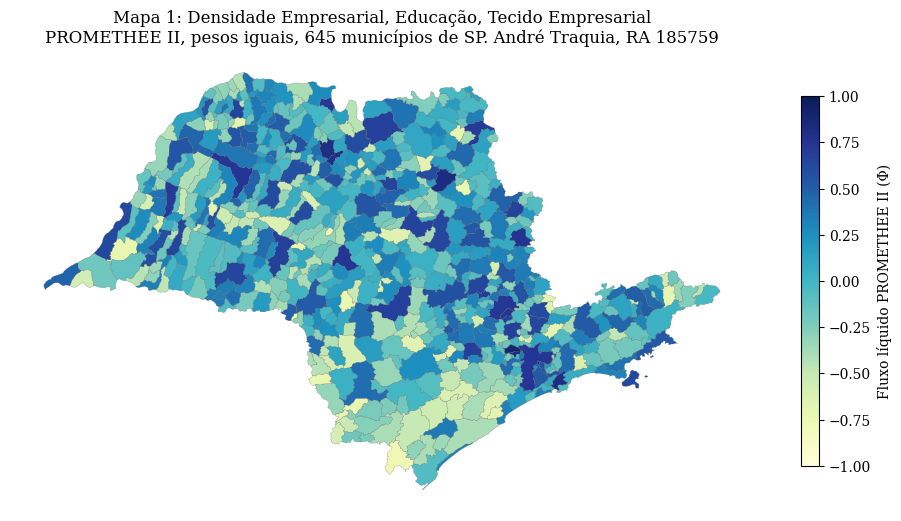

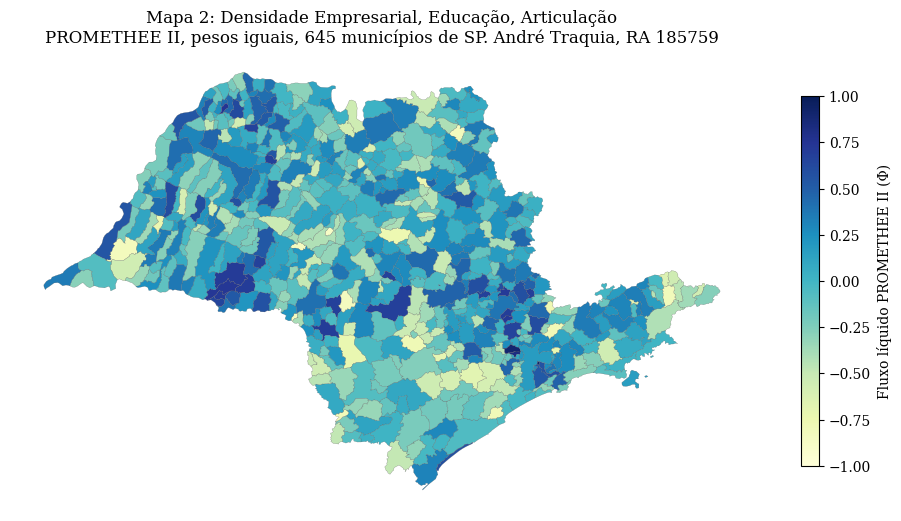

In [8]:
plt.rcParams['font.family'] = 'serif'

def mapa(r, criterios, titulo, arquivo):
    g = gdf_sp.merge(r[['codarea', 'Phi']], on='codarea')
    fig, ax = plt.subplots(figsize=(12, 8), facecolor='white')
    g.plot(column='Phi', cmap='YlGnBu', vmin=-1, vmax=1, linewidth=0.15, edgecolor='#555', ax=ax,
           legend=True, legend_kwds={'label': 'Fluxo líquido PROMETHEE II (Φ)', 'shrink': 0.6})
    ax.set_title(f'{titulo}: ' + ', '.join(criterios) + f'\nPROMETHEE II, pesos iguais, 645 municípios de SP. {ALUNO}, RA 185759', fontsize=12)
    ax.set_axis_off()
    fig.savefig(arquivo, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()

mapa(rA, COMB_A, 'Mapa 1', 'GL304_A3_mapa1.png')
mapa(rB, COMB_B, 'Mapa 2', 'GL304_A3_mapa2.png')

## 6. Comparação entre o Mapa 1 e o Mapa 2

Variação de posição = posição no Mapa 1 menos posição no Mapa 2. Valor positivo significa que o município **subiu** no Mapa 2.

In [9]:
comp = rA[['Município', 'Mesorregião', 'Microrregião', 'Tecido Empresarial']].copy()
comp['Articulação'] = rB['Articulação']
comp['Phi_1'], comp['Rank_1'] = rA['Phi'], rA['Ranking']
comp['Phi_2'], comp['Rank_2'] = rB['Phi'], rB['Ranking']
comp['Variação'] = comp['Rank_1'] - comp['Rank_2']
comp.sort_values('Variação', ascending=False).to_csv('GL304_A3_comparacao.csv', index=False, encoding='utf-8-sig')

print('Correlação de Spearman entre os dois rankings:', round(comp['Phi_1'].rank().corr(comp['Phi_2'].rank()), 3))
print('Variação absoluta mediana:', comp['Variação'].abs().median(), '| municípios que mudaram mais de 100 posições:', int((comp['Variação'].abs() > 100).sum()))
print('Top 10 em comum:', sorted(set(comp.nsmallest(10, 'Rank_1')['Município']) & set(comp.nsmallest(10, 'Rank_2')['Município'])))
print('Municípios com Tecido Empresarial = 0:', int((comp['Tecido Empresarial'] == 0).sum()), '| com Articulação = 0:', int((comp['Articulação'] == 0).sum()))
print('Desvio padrão de Phi: Mapa 1 =', round(comp['Phi_1'].std(), 3), '| Mapa 2 =', round(comp['Phi_2'].std(), 3))
print('\nQuem mais SUBIU do Mapa 1 para o Mapa 2:')
display(comp.nlargest(10, 'Variação').round(4))
print('Quem mais CAIU do Mapa 1 para o Mapa 2:')
display(comp.nsmallest(10, 'Variação').round(4))

Correlação de Spearman entre os dois rankings: 0.773
Variação absoluta mediana: 73.0 | municípios que mudaram mais de 100 posições: 231
Top 10 em comum: ['Barueri', 'Santana de Parnaíba', 'São Caetano do Sul']
Municípios com Tecido Empresarial = 0: 409 | com Articulação = 0: 206
Desvio padrão de Phi: Mapa 1 = 0.362 | Mapa 2 = 0.344

Quem mais SUBIU do Mapa 1 para o Mapa 2:


,Município,Mesorregião,Microrregião,Tecido Empresarial,Articulação,Phi_1,Rank_1,Phi_2,Rank_2,Variação
439,Pirapora do Bom Jesus,Metropolitana de São Paulo,Osasco,0.0,1.0000,-0.1781,432,0.2697,148,284
272,Itirapuã,Ribeirão Preto,Franca,0.0,1.0000,-0.2464,476,0.2013,194,282
114,Cândido Mota,Assis,Assis,0.0,1.0000,-0.2215,462,0.2262,181,281
495,Rio Grande da Serra,Metropolitana de São Paulo,São Paulo,0.0,1.0000,-0.2184,459,0.2293,179,280
284,Jambeiro,Vale do Paraíba Paulista,Paraibuna/Paraitinga,0.0,0.5833,-0.2308,469,0.1910,198,271
573,Sarutaiá,Assis,Ourinhos,0.0,0.9167,-0.2826,494,0.1537,224,270
433,Piquete,Vale do Paraíba Paulista,Guaratinguetá,0.0,0.9167,-0.1377,398,0.2987,131,267
587,Suzano,Metropolitana de São Paulo,Mogi das Cruzes,0.0,0.8333,-0.1408,399,0.2904,135,264
186,Florínia,Assis,Assis,0.0,1.0000,-0.0590,342,0.3887,80,262
488,Ribeirão Pires,Metropolitana de São Paulo,São Paulo,0.0,1.0000,-0.0569,341,0.3908,79,262


Quem mais CAIU do Mapa 1 para o Mapa 2:


,Município,Mesorregião,Microrregião,Tecido Empresarial,Articulação,Phi_1,Rank_1,Phi_2,Rank_2,Variação
226,Ibitinga,Araraquara,Araraquara,0.0040,0.0,0.3478,123,-0.1703,445,-322
257,Itapetininga,Itapetininga,Itapetininga,0.0042,0.0,0.2572,173,-0.2635,493,-320
2,Aguaí,Campinas,Pirassununga,0.0020,0.0,0.0854,257,-0.3970,556,-299
258,Itapeva,Itapetininga,Itapeva,0.0024,0.0,0.4193,91,-0.0771,386,-295
246,Ipuã,Ribeirão Preto,São Joaquim da Barra,0.0018,0.0,0.0352,284,-0.4405,576,-292
65,Bastos,Marília,Tupã,0.0014,0.0,0.2930,155,-0.1693,444,-289
331,Matão,Araraquara,Araraquara,0.0022,0.0,0.4431,76,-0.0450,362,-286
618,Tupã,Marília,Tupã,0.0012,0.0,0.2976,152,-0.1537,433,-281
132,Charqueada,Piracicaba,Piracicaba,0.0008,0.0,0.0663,263,-0.3504,543,-280
151,Cunha,Vale do Paraíba Paulista,Paraibuna/Paraitinga,0.0012,0.0,0.0305,291,-0.4208,568,-277


In [10]:
meso = comp.groupby('Mesorregião').agg(n=('Município', 'size'), Phi_medio_1=('Phi_1', 'mean'), Phi_medio_2=('Phi_2', 'mean'),
                                      Rank_medio_1=('Rank_1', 'mean'), Rank_medio_2=('Rank_2', 'mean'),
                                      Subiram=('Variação', lambda v: int((v > 0).sum())), Cairam=('Variação', lambda v: int((v < 0).sum())))
meso['Variação_media'] = meso['Rank_medio_1'] - meso['Rank_medio_2']
meso = meso.sort_values('Variação_media', ascending=False).round(3)
meso.to_csv('GL304_A3_mesorregioes.csv', encoding='utf-8-sig')
meso

,n,Phi_medio_1,Phi_medio_2,Rank_medio_1,Rank_medio_2,Subiram,Cairam,Variação_media
Mesorregião,,,,,,,,
Assis,35,0.016,0.191,311.857,222.857,26,9,89.000
Litoral Sul Paulista,17,-0.268,-0.098,453.647,381.118,12,5,72.529
Araçatuba,36,0.012,0.105,319.417,267.667,28,8,51.750
Campinas,49,0.178,0.192,233.531,219.959,28,21,13.571
Piracicaba,26,0.076,0.110,279.385,267.115,16,9,12.269
Presidente Prudente,54,-0.054,-0.039,351.037,342.278,27,27,8.759
Marília,20,-0.067,-0.047,357.800,350.600,13,7,7.200
Itapetininga,36,-0.223,-0.213,437.222,437.667,18,18,-0.444
Bauru,56,-0.098,-0.096,370.036,374.643,25,30,-4.607


In [11]:
micro = comp.groupby(['Mesorregião', 'Microrregião']).agg(n=('Município', 'size'), Rank_medio_1=('Rank_1', 'mean'), Rank_medio_2=('Rank_2', 'mean'))
micro['Variação_media'] = micro['Rank_medio_1'] - micro['Rank_medio_2']
micro = micro.sort_values('Variação_media', ascending=False).round(1)
print('Microrregiões que mais subiram:'); display(micro.head(8))
print('Microrregiões que mais caíram:'); display(micro.tail(8))

Microrregiões que mais subiram:


,,n,Rank_medio_1,Rank_medio_2,Variação_media
Mesorregião,Microrregião,,,,
Assis,Assis,17,276.9,129.1,147.8
Metropolitana de São Paulo,Franco da Rocha,4,427.8,295.2,132.5
Litoral Sul Paulista,Registro,12,479.3,355.7,123.7
Itapetininga,Capão Bonito,10,486.3,379.4,106.9
Campinas,Amparo,8,271.0,181.0,90.0
São José do Rio Preto,Jales,23,386.5,306.7,79.8
Ribeirão Preto,Batatais,6,286.2,210.0,76.2
Araçatuba,Andradina,11,348.5,273.5,75.0


Microrregiões que mais caíram:


,,n,Rank_medio_1,Rank_medio_2,Variação_media
Mesorregião,Microrregião,,,,
Itapetininga,Tatuí,9,331.1,422.1,-91.0
São José do Rio Preto,São José do Rio Preto,29,266.3,357.7,-91.3
Araraquara,Araraquara,15,353.7,449.9,-96.3
Ribeirão Preto,São Joaquim da Barra,9,271.0,372.1,-101.1
Metropolitana de São Paulo,Itapecerica da Serra,8,327.2,440.6,-113.4
Campinas,Pirassununga,4,203.8,380.5,-176.8
Metropolitana de São Paulo,Santos,6,217.0,396.8,-179.8
Vale do Paraíba Paulista,Caraguatatuba,4,82.5,314.0,-231.5
